In [25]:
import numpy as np
import matplotlib.pyplot as plt

definitions

In [29]:

def forward_haar_lifting(x):
    """
    Performs a 1-level 1D Forward Haar Wavelet Transform using the Lifting Scheme.
    Modifies data in-place or on a copy.
    """
    # Ensure working with floats and create a copy to protect original data
    arr = np.array(x, dtype=float)
    n = len(arr)
    assert n % 2 == 0, "Signal length must be even."
    
    # 1. Split into Even and Odd
    s = arr[0::2]  # Approximation (Even elements)
    d = arr[1::2]  # Details (Odd elements)
    
    # 2. Predict Step: d[i] = d[i] - s[i]
    d -= s
    
    # 3. Update Step: s[i] = s[i] + 0.5 * d[i]
    s += 0.5 * d
    
    # 4. Normalize (Optional: scales to match standard orthonormal DWT)
    s *= np.sqrt(2)
    d *= (1.0 / np.sqrt(2))
    
    # Interleave or return separated (standard returns approx, then details)
    return s, d

def inverse_haar_lifting(s, d):
    """
    Performs a 1-level 1D Inverse Haar Wavelet Transform using the Lifting Scheme.
    Reverses the operations of the forward transform in exact opposite order.
    """
    n = len(s) + len(d)
    
    # 1. Undo Normalization
    s /= np.sqrt(2)
    d /= (1.0 / np.sqrt(2))
    
    # 2. Undo Update Step: s[i] = s[i] - 0.5 * d[i]
    s -= 0.5 * d
    
    # 3. Undo Predict Step: d[i] = d[i] + s[i]
    d += s
    
    # 4. Merge Even and Odd back into one signal
    reconstructed = np.empty(n)
    reconstructed[0::2] = s
    reconstructed[1::2] = d
    
    return reconstructed


noisy signal gen

In [54]:
# Parameters
sampling_rate = 100  # Samples per second
duration = 1.0  # Total duration in seconds
freq = 5  # Frequency of the sine wave in Hz
noise_power = 0.2  # Amplitude of the random noise

# Time vector
t = np.arange(0, duration, 1 / sampling_rate)

# 1. Generate clean signal (Sine Wave)
clean_signal = np.sin(2 * np.pi * freq * t)

# 2. Generate random noise (Gaussian/Normal Distribution)
random_noise = np.random.normal(0, noise_power, t.shape)

# 3. Combine them to create the random signal
noisy_signal = clean_signal + random_noise

transformations

In [55]:

original_signal = noisy_signal
# Forward Transform
approx, diff = forward_haar_lifting(original_signal)

# Inverse Transform
reconstructed = inverse_haar_lifting(approx, diff)

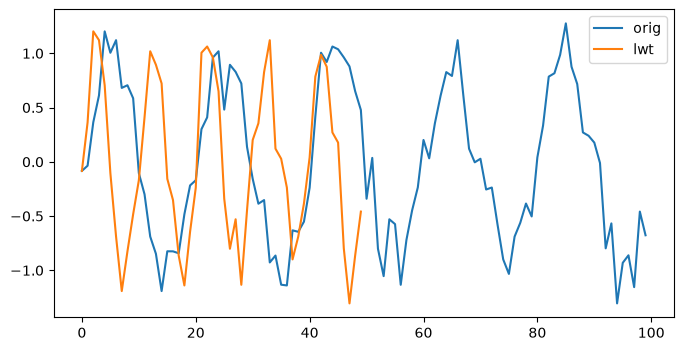

In [56]:
fig, ax = plt.subplots(figsize=(8,4))
approx_res = [sample for x in approx for sample in (x, float('nan'))]

ax.plot(original_signal, label="orig")
ax.plot(approx, label="lwt")
#ax.plot(reconstructed, label="reconst")

ax.legend()

In [57]:
original_signal

array([-0.08365182, -0.03580207,  0.36447889,  0.61177143,  1.20230197,
        1.00497002,  1.12114441,  0.68117977,  0.70559185,  0.58580008,
       -0.10378496, -0.2990923 , -0.68923748, -0.84771423, -1.19112723,
       -0.82446642, -0.82519933, -0.84298132, -0.48352729, -0.21753618,
       -0.17030759,  0.30078546,  0.40959687,  0.96089967,  1.01873452,
        0.48130124,  0.89415776,  0.82901123,  0.72229735,  0.13857435,
       -0.15695339, -0.38607312, -0.35263384, -0.92745832, -0.86391486,
       -1.1326189 , -1.13938119, -0.63161011, -0.64502212, -0.55148634,
       -0.23882839,  0.41639777,  1.00541789,  0.92021382,  1.06263228,
        1.03724365,  0.9626275 ,  0.87927623,  0.65002233,  0.47723231,
       -0.34042455,  0.03616844, -0.80113692, -1.05350167, -0.52965265,
       -0.5740936 , -1.13336588, -0.72043617, -0.44760717, -0.23600146,
        0.20143485,  0.0321615 ,  0.35496812,  0.60891858,  0.82688356,
        0.79128911,  1.12077266,  0.60974931,  0.1209213 , -0.00